In [1]:
import pandas as pd
import numpy as np

C:\Users\Rheah\anaconda3\lib\site-packages\pandas\core\computation\expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Rheah\anaconda3\lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


In [2]:
df=pd.read_csv('election_cleaned.csv')

In [3]:
df.head()



,username,text,likeCount,quoteCount,date,processed_text,Tokens,Filtered_Tokens,Lemmatized_Tokens,POS_Tags,cleaned_tweet
0,SATraveler2,@MdBreathe continued- \nto develop a techniqu...,0.0,0.0,2024-11-20 23:59:59,continue develop technique hide evidence human...,"['continue', 'develop', 'technique', 'hide', '...","['continue', 'develop', 'technique', 'hide', '...","['continue', 'develop', 'technique', 'hide', '...","[('continue', 'VERB'), (' \n ', 'SPACE'), ('de...",continued to develop a technique for hiding ev...
1,JoeZumwalt,@UROCKlive1 all these banderite/nazi sycophant...,0.0,0.0,2024-11-20 23:59:57,banderitenazi sycophant dnc,"['banderitenazi', 'sycophant', 'dnc']","['banderitenazi', 'sycophant', 'dnc']","['banderitenazi', 'sycophant', 'dnc']","[('banderitenazi', 'PROPN'), ('sycophant', 'PR...",all these banderitenazi sycophants to the dnc
2,67sharona,Laken Rileys Death Would Of Never Ever Happene...,1.0,0.0,2024-11-20 23:59:56,laken rileys death happen president justicefor...,"['laken', 'rileys', 'death', 'happen', 'presid...","['laken', 'rileys', 'death', 'happen', 'presid...","['laken', 'rileys', 'death', 'happen', 'presid...","[('laken', 'VERB'), ('rileys', 'PROPN'), ('dea...",laken rileys death would of never ever happene...
3,TruthAboutF,POV: you go downstairs in the middle of the ni...,14.0,0.0,2024-11-20 23:59:55,pov downstairs middle night bowl froot loop ft...,"['pov', 'downstairs', 'middle', 'night', 'bowl...","['pov', 'downstairs', 'middle', 'night', 'bowl...","['pov', 'downstairs', 'middle', 'night', 'bowl...","[('pov', 'PROPN'), ('downstairs', 'ADV'), ('mi...",pov you go downstairs in the middle of the nig...
4,Hump98Clint,"@mtgreenee This is a good question, are you no...",1.0,0.0,2024-11-20 23:59:53,good question member republican party list people,"['good', 'question', 'member', 'republican', '...","['good', 'question', 'member', 'republican', '...","['good', 'question', 'member', 'republican', '...","[('good', 'ADJ'), ('question', 'NOUN'), ('memb...",this is a good question are you not a member o...


In [11]:
import re
import pandas as pd
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Initialize VADER
analyzer = SentimentIntensityAnalyzer()

# Function to clean text (light preprocessing)
def clean_text(text):
    text = re.sub(r"http\S+", "", text)  # Remove URLs
    text = re.sub(r"@\w+", "", text)     # Remove mentions
    text = re.sub(r"[^A-Za-z0-9\s!?.,]", "", text)  # Keep letters, numbers, and common punctuation
    text = text.strip()  # Remove extra spaces
    return text

# Example tweets
tweets = [
    "@user1 This is AMAZING!!! 😂😂😂 Check this: http://link.com",
    "Ugh... I hate this so much. 😡",
    "Not bad, but could be better!",
]

# Apply cleaning + sentiment analysis
for tweet in tweets:
    cleaned_tweet = clean_text(tweet)
    score = analyzer.polarity_scores(cleaned_tweet)
    print(f"Original: {tweet}")
    print(f"Cleaned: {cleaned_tweet}")
    print(f"Sentiment Scores: {score}\n")


Original: @user1 This is AMAZING!!! 😂😂😂 Check this: http://link.com
Cleaned: This is AMAZING!!!  Check this
Sentiment Scores: {'neg': 0.0, 'neu': 0.425, 'pos': 0.575, 'compound': 0.7513}

Original: Ugh... I hate this so much. 😡
Cleaned: Ugh... I hate this so much.
Sentiment Scores: {'neg': 0.619, 'neu': 0.381, 'pos': 0.0, 'compound': -0.7579}

Original: Not bad, but could be better!
Cleaned: Not bad, but could be better!
Sentiment Scores: {'neg': 0.0, 'neu': 0.397, 'pos': 0.603, 'compound': 0.7242}



# Labelling using Vader

In [4]:
import pandas as pd
import re
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Load dataset
df = pd.read_csv('election.csv')

# Initialize VADER
analyzer = SentimentIntensityAnalyzer()

# Function to analyze sentiment
def get_vader_sentiment(text):
    if isinstance(text, str):  # Ensure it's a string
        score = analyzer.polarity_scores(text)
        return score['compound']  # Extract compound score
    return 0  # Default if text is missing

# Apply sentiment analysis to 'cleaned_tweet' column
df['sentiment_score'] = df['text'].apply(get_vader_sentiment)

# Label sentiment based on compound score
def label_sentiment(score):
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

df['sentiment_label'] = df['sentiment_score'].apply(label_sentiment)

# Save results to a new CSV
df.to_csv('election_sentiment.csv', index=False)

# Display sample results
print(df[['text', 'sentiment_score', 'sentiment_label']].head(20))


                                                 text  sentiment_score  \
0   @MdBreathe continued-  \nto develop a techniqu...           0.4019   
1   @UROCKlive1 all these banderite/nazi sycophant...           0.0000   
2   Laken Rileys Death Would Of Never Ever Happene...          -0.8469   
3   POV: you go downstairs in the middle of the ni...           0.0000   
4   @mtgreenee This is a good question, are you no...           0.7149   
5   The race is on for the next DNC chair. Martin ...           0.0000   
6   @DefiyantlyFree Kamala Harris is a leech grift...          -0.8439   
7   @BarronTrumpoo Kamala Harris is Vice President...          -0.7315   
8   @MayorOfLA @POTUS A Pew study this year fall s...           0.6848   
9            @TheDemocrats Wtf are you doing Montana?          -0.5859   
10  @konsem @AAkerstein @peanutnewz @SenSanders De...           0.3400   
11  🎉 BREAKING NEWS! 🎉\n\nVivek Ramaswamy just ann...           0.8475   
12                                    

In [6]:
DF1=pd.read_csv('election_sentiment.csv')

In [7]:
DF1.head()

,username,text,likeCount,quoteCount,date,processed_text,Tokens,Filtered_Tokens,Lemmatized_Tokens,POS_Tags,cleaned_tweet,sentiment_score,sentiment_label
0,SATraveler2,@MdBreathe continued- \nto develop a techniqu...,0.0,0.0,2024-11-20 23:59:59,continue develop technique hide evidence human...,"['continue', 'develop', 'technique', 'hide', '...","['continue', 'develop', 'technique', 'hide', '...","['continue', 'develop', 'technique', 'hide', '...","[('continue', 'VERB'), (' \n ', 'SPACE'), ('de...",continued to develop a technique for hiding ev...,0.4019,Positive
1,JoeZumwalt,@UROCKlive1 all these banderite/nazi sycophant...,0.0,0.0,2024-11-20 23:59:57,banderitenazi sycophant dnc,"['banderitenazi', 'sycophant', 'dnc']","['banderitenazi', 'sycophant', 'dnc']","['banderitenazi', 'sycophant', 'dnc']","[('banderitenazi', 'PROPN'), ('sycophant', 'PR...",all these banderitenazi sycophants to the dnc,0.0000,Neutral
2,67sharona,Laken Rileys Death Would Of Never Ever Happene...,1.0,0.0,2024-11-20 23:59:56,laken rileys death happen president justicefor...,"['laken', 'rileys', 'death', 'happen', 'presid...","['laken', 'rileys', 'death', 'happen', 'presid...","['laken', 'rileys', 'death', 'happen', 'presid...","[('laken', 'VERB'), ('rileys', 'PROPN'), ('dea...",laken rileys death would of never ever happene...,-0.5994,Negative
3,TruthAboutF,POV: you go downstairs in the middle of the ni...,14.0,0.0,2024-11-20 23:59:55,pov downstairs middle night bowl froot loop ft...,"['pov', 'downstairs', 'middle', 'night', 'bowl...","['pov', 'downstairs', 'middle', 'night', 'bowl...","['pov', 'downstairs', 'middle', 'night', 'bowl...","[('pov', 'PROPN'), ('downstairs', 'ADV'), ('mi...",pov you go downstairs in the middle of the nig...,0.0000,Neutral
4,Hump98Clint,"@mtgreenee This is a good question, are you no...",1.0,0.0,2024-11-20 23:59:53,good question member republican party list people,"['good', 'question', 'member', 'republican', '...","['good', 'question', 'member', 'republican', '...","['good', 'question', 'member', 'republican', '...","[('good', 'ADJ'), ('question', 'NOUN'), ('memb...",this is a good question are you not a member o...,0.6808,Positive


In [5]:
import pandas as pd
import re
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Load dataset
df = pd.read_csv('election_cleaned.csv')

# Initialize VADER
analyzer = SentimentIntensityAnalyzer()

# Function to analyze sentiment
def get_vader_sentiment(text):
    if isinstance(text, str):  # Ensure it's a string
        score = analyzer.polarity_scores(text)
        return score['compound']  # Extract compound score
    return 0  # Default if text is missing

# Apply sentiment analysis to 'cleaned_tweet' column
df['sentiment_score'] = df['cleaned_tweet'].apply(get_vader_sentiment)

# Label sentiment based on compound score
def label_sentiment(score):
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

df['sentiment_label'] = df['sentiment_score'].apply(label_sentiment)

# Save results to a new CSV
df.to_csv('election_sentiment.csv', index=False)

# Display sample results
print(df[['cleaned_tweet', 'sentiment_score', 'sentiment_label']].head(20))


                                        cleaned_tweet  sentiment_score  \
0   continued to develop a technique for hiding ev...           0.4019   
1       all these banderitenazi sycophants to the dnc           0.0000   
2   laken rileys death would of never ever happene...          -0.5994   
3   pov you go downstairs in the middle of the nig...           0.0000   
4   this is a good question are you not a member o...           0.6808   
5   the race is on for the next dnc chair martin o...           0.0000   
6   kamala harris is a leech grifter who has done ...          -0.8316   
7   kamala harris is vice presidentwe may not like...          -0.8383   
8   a pew study this year fall showed that immigra...           0.6848   
9                           wtf are you doing montana          -0.5859   
10  democratic party needs a serious re work anyon...           0.3400   
11  breaking news vivek ramaswamy just announced h...           0.1531   
12                                    

# Kmeans

In [21]:
df["cleaned_tweet"] = df["cleaned_tweet"].fillna("")

# Now apply TF-IDF
vectorizer = TfidfVectorizer(max_features=5000)
X = vectorizer.fit_transform(df["cleaned_tweet"])


In [35]:
import pandas as pd

df = pd.read_csv("election_cleaned.csv")

# Check for NaN values
print(df["cleaned_tweet"].isna().sum())  # Count missing values
print(df.dtypes)  # Check the data types


1771
username              object
text                  object
likeCount            float64
quoteCount           float64
date                  object
processed_text        object
Tokens                object
Filtered_Tokens       object
Lemmatized_Tokens     object
POS_Tags              object
cleaned_tweet         object
dtype: object


In [24]:
df["cleaned_tweet"] = df["cleaned_tweet"].fillna("")


In [25]:
df["cleaned_tweet"] = df["cleaned_tweet"].astype(str)


In [36]:
print(df["cleaned_tweet"].isna().sum())  # Count missing values
print(df.dtypes)  # Check the data types

1771
username              object
text                  object
likeCount            float64
quoteCount           float64
date                  object
processed_text        object
Tokens                object
Filtered_Tokens       object
Lemmatized_Tokens     object
POS_Tags              object
cleaned_tweet         object
dtype: object


In [37]:
df = df.dropna(subset=["cleaned_tweet"])


In [38]:
print(df["cleaned_tweet"].isna().sum())  # Count missing values
print(df.dtypes)  # Check the data types

0
username              object
text                  object
likeCount            float64
quoteCount           float64
date                  object
processed_text        object
Tokens                object
Filtered_Tokens       object
Lemmatized_Tokens     object
POS_Tags              object
cleaned_tweet         object
dtype: object


In [30]:
df.shape

(48229, 11)

In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans


# Convert text to numerical features using TF-IDF
vectorizer = TfidfVectorizer(max_features=5000)
X = vectorizer.fit_transform(df["cleaned_tweet"])

# Apply K-Means Clustering (AAssuming 3 clusters: Positive, Neutral, Negative)
num_clusters = 3  
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X)

# View sample clustered tweets
print(df.groupby("cluster")["cleaned_tweet"].head(5))  

0     continued to develop a technique for hiding ev...
1         all these banderitenazi sycophants to the dnc
2     laken rileys death would of never ever happene...
3     pov you go downstairs in the middle of the nig...
4     this is a good question are you not a member o...
5     the race is on for the next dnc chair martin o...
6     kamala harris is a leech grifter who has done ...
7     kamala harris is vice presidentwe may not like...
8     a pew study this year fall showed that immigra...
9                             wtf are you doing montana
10    democratic party needs a serious re work anyon...
11    breaking news vivek ramaswamy just announced h...
13    maybe for the senate there are only 100 of the...
20    vp kamala harris must demand a handrecount amp...
22    the 25th amendment would automatically give pr...
Name: cleaned_tweet, dtype: object


In [40]:
df.shape

(48229, 12)

In [41]:
print(df["cluster"].value_counts())


cluster
2    24857
1    17153
0     6219
Name: count, dtype: int64


In [45]:
cluster_labels = {0: "Negative", 1: "Neutral", 2: "Positive"}
df["sentiment"] = df["cluster"].map(cluster_labels)


In [47]:
df.head(10)

,username,text,likeCount,quoteCount,date,processed_text,Tokens,Filtered_Tokens,Lemmatized_Tokens,POS_Tags,cleaned_tweet,cluster,sentiment
0,SATraveler2,@MdBreathe continued- \nto develop a techniqu...,0.0,0.0,2024-11-20 23:59:59,continue develop technique hide evidence human...,"['continue', 'develop', 'technique', 'hide', '...","['continue', 'develop', 'technique', 'hide', '...","['continue', 'develop', 'technique', 'hide', '...","[('continue', 'VERB'), (' \n ', 'SPACE'), ('de...",continued to develop a technique for hiding ev...,2,Positive
1,JoeZumwalt,@UROCKlive1 all these banderite/nazi sycophant...,0.0,0.0,2024-11-20 23:59:57,banderitenazi sycophant dnc,"['banderitenazi', 'sycophant', 'dnc']","['banderitenazi', 'sycophant', 'dnc']","['banderitenazi', 'sycophant', 'dnc']","[('banderitenazi', 'PROPN'), ('sycophant', 'PR...",all these banderitenazi sycophants to the dnc,1,Neutral
2,67sharona,Laken Rileys Death Would Of Never Ever Happene...,1.0,0.0,2024-11-20 23:59:56,laken rileys death happen president justicefor...,"['laken', 'rileys', 'death', 'happen', 'presid...","['laken', 'rileys', 'death', 'happen', 'presid...","['laken', 'rileys', 'death', 'happen', 'presid...","[('laken', 'VERB'), ('rileys', 'PROPN'), ('dea...",laken rileys death would of never ever happene...,2,Positive
3,TruthAboutF,POV: you go downstairs in the middle of the ni...,14.0,0.0,2024-11-20 23:59:55,pov downstairs middle night bowl froot loop ft...,"['pov', 'downstairs', 'middle', 'night', 'bowl...","['pov', 'downstairs', 'middle', 'night', 'bowl...","['pov', 'downstairs', 'middle', 'night', 'bowl...","[('pov', 'PROPN'), ('downstairs', 'ADV'), ('mi...",pov you go downstairs in the middle of the nig...,2,Positive
4,Hump98Clint,"@mtgreenee This is a good question, are you no...",1.0,0.0,2024-11-20 23:59:53,good question member republican party list people,"['good', 'question', 'member', 'republican', '...","['good', 'question', 'member', 'republican', '...","['good', 'question', 'member', 'republican', '...","[('good', 'ADJ'), ('question', 'NOUN'), ('memb...",this is a good question are you not a member o...,1,Neutral
5,BlakeBurman,The race is on for the next DNC chair. Martin ...,3.0,1.0,2024-11-20 23:59:51,race dnc chair martin omalley join tv intervie...,"['race', 'dnc', 'chair', 'martin', 'omalley', ...","['race', 'dnc', 'chair', 'martin', 'omalley', ...","['race', 'dnc', 'chair', 'martin', 'omalley', ...","[('race', 'NOUN'), ('dnc', 'PROPN'), ('chair',...",the race is on for the next dnc chair martin o...,1,Neutral
6,Chip_quicksteps,@DefiyantlyFree Kamala Harris is a leech grift...,0.0,0.0,2024-11-20 23:59:50,kamala harris leech grifter run mouth tell lie...,"['kamala', 'harris', 'leech', 'grifter', 'run'...","['kamala', 'harris', 'leech', 'grifter', 'run'...","['kamala', 'harris', 'leech', 'grifter', 'run'...","[('kamala', 'PROPN'), ('harris', 'PROPN'), ('l...",kamala harris is a leech grifter who has done ...,0,Negative
7,Cynthia19941119,@BarronTrumpoo Kamala Harris is Vice President...,0.0,0.0,2024-11-20 23:59:49,kamala harris vice presidentwe like stupid,"['kamala', 'harris', 'vice', 'presidentwe', 'l...","['kamala', 'harris', 'vice', 'presidentwe', 'l...","['kamala', 'harris', 'vice', 'presidentwe', 'l...","[('kamala', 'PROPN'), ('harris', 'PROPN'), ('v...",kamala harris is vice presidentwe may not like...,0,Negative
8,G2638Garr,@MayorOfLA @POTUS A Pew study this year fall s...,0.0,0.0,2024-11-20 23:59:49,pew study year fall show immigration important...,"['pew', 'study', 'year', 'fall', 'show', 'immi...","['pew', 'study', 'year', 'fall', 'immigration'...","['pew', 'study', 'year', 'fall', 'show', 'immi...","[('pew', 'NOUN'), ('study', 'NOUN'), ('year', ...",a pew study this year fall showed that immigra...,0,Negative
9,mascotmike12,@TheDemocrats Wtf are you doing Montana?,7.0,0.0,2024-11-20 23:59:45,wtf montana,"['wtf', 'montana']","['wtf', 'montana']","['wtf', 'montana']","[('wtf', 'PROPN'), ('montana', 'PROPN')]",wtf are you doing montana,2,

In [44]:
for cluster in range(3):
    print(f"\nCluster {cluster} Examples:")
    print(df[df["cluster"] == cluster]["cleaned_tweet"].sample(5, random_state=42).tolist())



Cluster 0 Examples:
['angela bassett as president is what kamala harris thinks she is', 'in other words you refuse to be another kamala harris good for you', 'i believe that kamala harris needs to be arrested as well she had control of the border and is influencing sanctuary cities not to abide by federal law', 'newsmax exposed kamala harris and the radical left with this bonechilling revelation a map charting state voter id requirements shows that kamala harris only won states that do not require id', 'they should put kamala harris on supreme court']

Cluster 1 Examples:
['you still havent learned anything from nov 5th electionthats when president trump crushed the democratic party out of existence', 'it was before he bought it yes thats why i said peak was right after he bought for around 6 months but this place could be so much better i still miss third party apps elon could have just made them pay the x branding although decent feels lifeless and well yhea the bot', 'watching the 

# LDA

In [8]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Convert text to numerical features using BoW
vectorizer = CountVectorizer(max_features=5000, stop_words="english")
X = vectorizer.fit_transform(df["cleaned_tweet"].dropna())  # Drop NaNs

# Apply LDA (Assuming 3 topics)
num_topics = 3  
lda = LatentDirichletAllocation(n_components=num_topics, random_state=42)
X_topics = lda.fit_transform(X)

# Assign dominant topic to each tweet
df = df.loc[df["cleaned_tweet"].notna()]  # Keep only non-null tweets
df["topic"] = X_topics.argmax(axis=1)

# View sample clustered tweets
print(df.groupby("topic")["cleaned_tweet"].head(5))


0     continued to develop a technique for hiding ev...
1         all these banderitenazi sycophants to the dnc
2     laken rileys death would of never ever happene...
3     pov you go downstairs in the middle of the nig...
4     this is a good question are you not a member o...
5     the race is on for the next dnc chair martin o...
6     kamala harris is a leech grifter who has done ...
7     kamala harris is vice presidentwe may not like...
8     a pew study this year fall showed that immigra...
9                             wtf are you doing montana
10    democratic party needs a serious re work anyon...
11    breaking news vivek ramaswamy just announced h...
12                                             可愛いな噛み締め
13    maybe for the senate there are only 100 of the...
14    keep the pressure on im willing to not argue a...
Name: cleaned_tweet, dtype: object


In [9]:
def print_topics(model, feature_names, num_words=10):
    for topic_idx, topic in enumerate(model.components_):
        print(f"\nTopic {topic_idx}:")
        print(", ".join([feature_names[i] for i in topic.argsort()[:-num_words - 1:-1]]))

print_topics(lda, vectorizer.get_feature_names())   



Topic 0:
trump, jr, party, donald, dnc, maga, world, war, president, amp

Topic 1:
kamala, harris, biden, joe, dnc, president, vivek, campaign, ramaswamy, did

Topic 2:
party, rfk, jr, democratic, republican, people, like, dont, just, dnc


In [13]:
import pandas as pd

# Load dataset (assuming df already exists after LDA)
# Ensure "sentiment_label" and "topic" columns are present
if "topic" not in df.columns or "sentiment_label" not in df.columns:
    raise KeyError("Ensure 'topic' and 'sentiment_label' columns exist in the dataframe.")

# Filter only positive sentiment tweets from topic 0 and topic 1
positive_tweets = df[(df["sentiment_label"] == "Positive") & (df["topic"].isin([0, 1]))]

# Count positive tweets per topic
positive_topic_counts = positive_tweets["topic"].value_counts()

# Find the topic with the highest positive sentiment
top_topic = positive_topic_counts.idxmax()

print(f"Topic with the highest positive sentiment (between 0 and 1): Topic {top_topic}")


Topic with the highest positive sentiment (between 0 and 1): Topic 1


In [14]:
import pandas as pd

# Load dataset (assuming df already exists after LDA)
# Ensure "sentiment_label" and "topic" columns are present
if "topic" not in df.columns or "sentiment_label" not in df.columns:
    raise KeyError("Ensure 'topic' and 'sentiment_label' columns exist in the dataframe.")

# Filter tweets with Positive or Neutral sentiment from topics 0 and 1
filtered_tweets = df[(df["sentiment_label"].isin(["Positive", "Neutral"])) & (df["topic"].isin([0, 1]))]

# Count tweets per topic
sentiment_topic_counts = filtered_tweets["topic"].value_counts()

# Determine who had more Positive + Neutral sentiment
top_figure = "Donald Trump" if sentiment_topic_counts.get(0, 0) > sentiment_topic_counts.get(1, 0) else "Kamala Harris"

print(f"The person with more Positive + Neutral sentiment: {top_figure}")


The person with more Positive + Neutral sentiment: Kamala Harris


In [15]:
import pandas as pd

# Load dataset (assuming df already exists after LDA)
# Ensure "sentiment_label" and "topic" columns are present
if "topic" not in df.columns or "sentiment_label" not in df.columns:
    raise KeyError("Ensure 'topic' and 'sentiment_label' columns exist in the dataframe.")

# Filter tweets with Positive or Neutral sentiment from topics 0 and 1
filtered_tweets = df[(df["sentiment_label"].isin([ "Negative"])) & (df["topic"].isin([0, 1]))]

# Count tweets per topic
sentiment_topic_counts = filtered_tweets["topic"].value_counts()

# Determine who had more Positive + Neutral sentiment
top_figure = "Donald Trump" if sentiment_topic_counts.get(0, 0) > sentiment_topic_counts.get(1, 0) else "Kamala Harris"

print(f"The person with more Negative sentiment: {top_figure}")


The person with more Negative sentiment: Kamala Harris


In [16]:
# Load dataset (assuming df already exists after LDA)
# Ensure "sentiment_label" and "topic" columns are present
if "topic" not in df.columns or "sentiment_label" not in df.columns:
    raise KeyError("Ensure 'topic' and 'sentiment_label' columns exist in the dataframe.")

# Filter only positive sentiment tweets from topic 0 and topic 1
negative_tweets = df[(df["sentiment_label"] == "Negative") & (df["topic"].isin([0, 1]))]

# Count positive tweets per topic
negative_topic_counts = negative_tweets["topic"].value_counts()

# Find the topic with the highest positive sentiment
top_topic = negative_topic_counts.idxmax()

print(f"Topic with the highest negative sentiment (between 0 and 1): Topic {top_topic}")

Topic with the highest negative sentiment (between 0 and 1): Topic 1


KeyError: "Missing required columns: {'topic'}"

In [19]:
df.head()

,username,text,likeCount,quoteCount,date,processed_text,Tokens,Filtered_Tokens,Lemmatized_Tokens,POS_Tags,cleaned_tweet,sentiment_score,sentiment_label
0,SATraveler2,@MdBreathe continued- \nto develop a techniqu...,0.0,0.0,2024-11-20 23:59:59,continue develop technique hide evidence human...,"['continue', 'develop', 'technique', 'hide', '...","['continue', 'develop', 'technique', 'hide', '...","['continue', 'develop', 'technique', 'hide', '...","[('continue', 'VERB'), (' \n ', 'SPACE'), ('de...",continued to develop a technique for hiding ev...,0.4019,Positive
1,JoeZumwalt,@UROCKlive1 all these banderite/nazi sycophant...,0.0,0.0,2024-11-20 23:59:57,banderitenazi sycophant dnc,"['banderitenazi', 'sycophant', 'dnc']","['banderitenazi', 'sycophant', 'dnc']","['banderitenazi', 'sycophant', 'dnc']","[('banderitenazi', 'PROPN'), ('sycophant', 'PR...",all these banderitenazi sycophants to the dnc,0.0000,Neutral
2,67sharona,Laken Rileys Death Would Of Never Ever Happene...,1.0,0.0,2024-11-20 23:59:56,laken rileys death happen president justicefor...,"['laken', 'rileys', 'death', 'happen', 'presid...","['laken', 'rileys', 'death', 'happen', 'presid...","['laken', 'rileys', 'death', 'happen', 'presid...","[('laken', 'VERB'), ('rileys', 'PROPN'), ('dea...",laken rileys death would of never ever happene...,-0.5994,Negative
3,TruthAboutF,POV: you go downstairs in the middle of the ni...,14.0,0.0,2024-11-20 23:59:55,pov downstairs middle night bowl froot loop ft...,"['pov', 'downstairs', 'middle', 'night', 'bowl...","['pov', 'downstairs', 'middle', 'night', 'bowl...","['pov', 'downstairs', 'middle', 'night', 'bowl...","[('pov', 'PROPN'), ('downstairs', 'ADV'), ('mi...",pov you go downstairs in the middle of the nig...,0.0000,Neutral
4,Hump98Clint,"@mtgreenee This is a good question, are you no...",1.0,0.0,2024-11-20 23:59:53,good question member republican party list people,"['good', 'question', 'member', 'republican', '...","['good', 'question', 'member', 'republican', '...","['good', 'question', 'member', 'republican', '...","[('good', 'ADJ'), ('question', 'NOUN'), ('memb...",this is a good question are you not a member o...,0.6808,Positive


In [20]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Convert text to numerical features using BoW
vectorizer = CountVectorizer(max_features=5000, stop_words="english")
X = vectorizer.fit_transform(df["cleaned_tweet"].dropna())  # Drop NaNs

# Apply LDA (assuming 3 topics, adjust if needed)
num_topics = 3  
lda = LatentDirichletAllocation(n_components=num_topics, random_state=42)
X_topics = lda.fit_transform(X)

# Assign dominant topic to each tweet
df = df.loc[df["cleaned_tweet"].notna()]  # Keep only non-null tweets
df["topic"] = X_topics.argmax(axis=1)


C:\Users\Rheah\AppData\Local\Temp/ipykernel_21488/1157007869.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["topic"] = X_topics.argmax(axis=1)


In [21]:
df.head()

,username,text,likeCount,quoteCount,date,processed_text,Tokens,Filtered_Tokens,Lemmatized_Tokens,POS_Tags,cleaned_tweet,sentiment_score,sentiment_label,topic
0,SATraveler2,@MdBreathe continued- \nto develop a techniqu...,0.0,0.0,2024-11-20 23:59:59,continue develop technique hide evidence human...,"['continue', 'develop', 'technique', 'hide', '...","['continue', 'develop', 'technique', 'hide', '...","['continue', 'develop', 'technique', 'hide', '...","[('continue', 'VERB'), (' \n ', 'SPACE'), ('de...",continued to develop a technique for hiding ev...,0.4019,Positive,0
1,JoeZumwalt,@UROCKlive1 all these banderite/nazi sycophant...,0.0,0.0,2024-11-20 23:59:57,banderitenazi sycophant dnc,"['banderitenazi', 'sycophant', 'dnc']","['banderitenazi', 'sycophant', 'dnc']","['banderitenazi', 'sycophant', 'dnc']","[('banderitenazi', 'PROPN'), ('sycophant', 'PR...",all these banderitenazi sycophants to the dnc,0.0000,Neutral,0
2,67sharona,Laken Rileys Death Would Of Never Ever Happene...,1.0,0.0,2024-11-20 23:59:56,laken rileys death happen president justicefor...,"['laken', 'rileys', 'death', 'happen', 'presid...","['laken', 'rileys', 'death', 'happen', 'presid...","['laken', 'rileys', 'death', 'happen', 'presid...","[('laken', 'VERB'), ('rileys', 'PROPN'), ('dea...",laken rileys death would of never ever happene...,-0.5994,Negative,1
3,TruthAboutF,POV: you go downstairs in the middle of the ni...,14.0,0.0,2024-11-20 23:59:55,pov downstairs middle night bowl froot loop ft...,"['pov', 'downstairs', 'middle', 'night', 'bowl...","['pov', 'downstairs', 'middle', 'night', 'bowl...","['pov', 'downstairs', 'middle', 'night', 'bowl...","[('pov', 'PROPN'), ('downstairs', 'ADV'), ('mi...",pov you go downstairs in the middle of the nig...,0.0000,Neutral,2
4,Hump98Clint,"@mtgreenee This is a good question, are you no...",1.0,0.0,2024-11-20 23:59:53,good question member republican party list people,"['good', 'question', 'member', 'republican', '...","['good', 'question', 'member', 'republican', '...","['good', 'question', 'member', 'republican', '...","[('good', 'ADJ'), ('question', 'NOUN'), ('memb...",this is a good question are you not a member o...,0.6808,Positive,2


In [22]:


# Ensure necessary columns exist
required_columns = {"sentiment_label", "topic"}
if not required_columns.issubset(df.columns):
    raise KeyError(f"Missing required columns: {required_columns - set(df.columns)}")

# Define topics for candidates
candidate_topics = {0: "Donald Trump", 1: "Kamala Harris"}  

# Filter relevant topics
df = df[df["topic"].isin(candidate_topics.keys())]

# Count sentiment per candidate
sentiment_counts = df.groupby(["topic", "sentiment_label"]).size().unstack(fill_value=0)

# Compute overall sentiment score
sentiment_counts["Overall_Score"] = sentiment_counts.get("Positive", 0) - sentiment_counts.get("Negative", 0)

# Determine the predicted winner
predicted_winner_topic = sentiment_counts["Overall_Score"].idxmax()
predicted_winner = candidate_topics[predicted_winner_topic]

print(f"Predicted Winner of the 2024 US Elections: {predicted_winner}")


Predicted Winner of the 2024 US Elections: Donald Trump


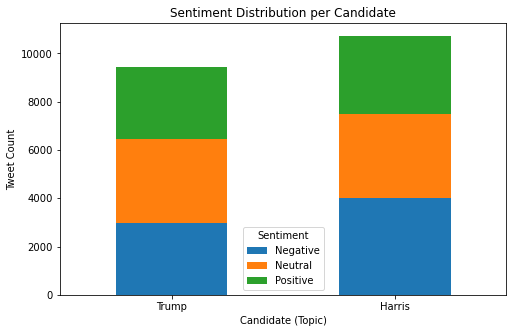

In [24]:
import matplotlib.pyplot as plt

# Plot sentiment distribution per candidate
sentiment_counts.drop(columns=["Overall_Score"]).plot(kind="bar", stacked=True, figsize=(8,5))
plt.xlabel("Candidate (Topic)")
plt.ylabel("Tweet Count")
plt.title("Sentiment Distribution per Candidate")
plt.legend(title="Sentiment")
plt.xticks(ticks=[0,1], labels=["Trump", "Harris"], rotation=0)
plt.show()
